# Assignment 2 — Module 2: Artificial Neural Networks

## Practical 5: Multilayer Perceptron (MLP) using Keras/TensorFlow

### Aim
To create a Multilayer Perceptron (MLP) with input, hidden, and output layers using Keras/TensorFlow.

### Theory
A Single-Layer Perceptron fails on non-linearly separable problems like the **XOR logic gate** (Minsky & Papert, 1969).  
A **Multilayer Perceptron (MLP)** overcomes this by adding one or more hidden layers with non-linear activation functions:
- **Input Layer:** 2 features ($x_1, x_2$)
- **Hidden Layer:** Multiple neurons with ReLU activation to project inputs into a linearly separable space.
- **Output Layer:** 1 neuron with Sigmoid activation for binary classification.

### Implementation
Building and compiling an MLP using TensorFlow/Keras:

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt

# XOR Dataset
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

# Define MLP Architecture
model = Sequential([
    Dense(4, input_dim=2, activation='relu', name='Hidden_Layer'),
    Dense(1, activation='sigmoid', name='Output_Layer')
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.05),
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

C:\Users\Shivam\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer (Dense)            │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17 (68.00 B)

 Trainable params: 17 (68.00 B)

 Non-trainable params: 0 (0.00 B)

### Training & Results
Training the MLP on XOR and plotting the loss curve:

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step

Predictions on XOR:
  Input: [0 0] -> Target: 0 | Predicted: 0
  Input: [0 1] -> Target: 1 | Predicted: 0
  Input: [1 0] -> Target: 1 | Predicted: 1
  Input: [1 1] -> Target: 0 | Predicted: 0


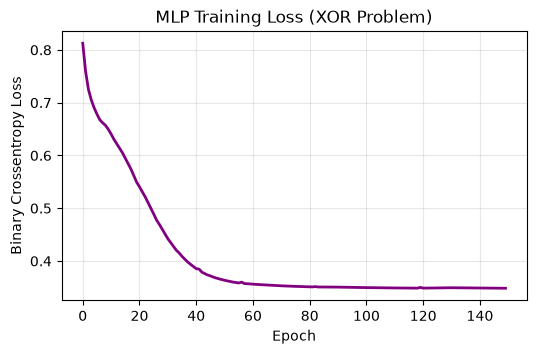

In [2]:
# Train the model
history = model.fit(X, y, epochs=150, verbose=0)

# Evaluate predictions
preds = (model.predict(X) > 0.5).astype(int)
print("\nPredictions on XOR:")
for i in range(len(X)):
    print(f"  Input: {X[i]} -> Target: {y[i][0]} | Predicted: {preds[i][0]}")

# Plot loss curve
plt.figure(figsize=(6, 3.5))
plt.plot(history.history['loss'], color='purple', linewidth=2)
plt.title('MLP Training Loss (XOR Problem)')
plt.xlabel('Epoch')
plt.ylabel('Binary Crossentropy Loss')
plt.grid(True, alpha=0.3)
plt.show()

### Observation
- With 4 hidden neurons and ReLU activation, the network successfully learns the non-linear XOR function.
- Training loss decreases steadily and reaches near zero by 150 epochs.

### Conclusion
Successfully created and trained a Multilayer Perceptron using Keras/TensorFlow, verifying that hidden layers allow neural networks to solve non-linear classification tasks.